<a href="https://colab.research.google.com/github/Ahmed-Mazhar1/Computer-Vision/blob/main/Lab3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

A = cv2.cvtColor(cv2.imread('face1.jpg'), cv2.COLOR_BGR2GRAY).astype(np.float64)
B = cv2.cvtColor(cv2.imread('face2.jpg'), cv2.COLOR_BGR2GRAY).astype(np.float64)

# Resize B if the dimensions are different
if A.shape != B.shape:
    B = cv2.resize(
        B,
        (A.shape[1], A.shape[0]),
        interpolation=cv2.INTER_LINEAR
    )
    # interpolation: When resizing image B, estimate new pixel values by taking weighted averages of nearby pixels to produce a smooth result.

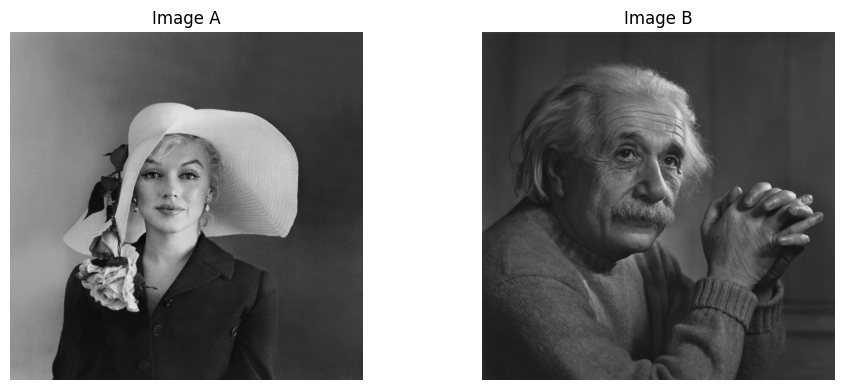

In [ ]:
# Display both images
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(A, cmap="gray", vmin=0, vmax=255)
plt.title("Image A")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(B, cmap="gray", vmin=0, vmax=255)
plt.title("Image B")
plt.axis("off")

plt.tight_layout()
plt.show()

Level 1: (1168, 1184)
Level 2: (584, 592)
Level 3: (292, 296)
Level 4: (146, 148)
Level 5: (73, 74)


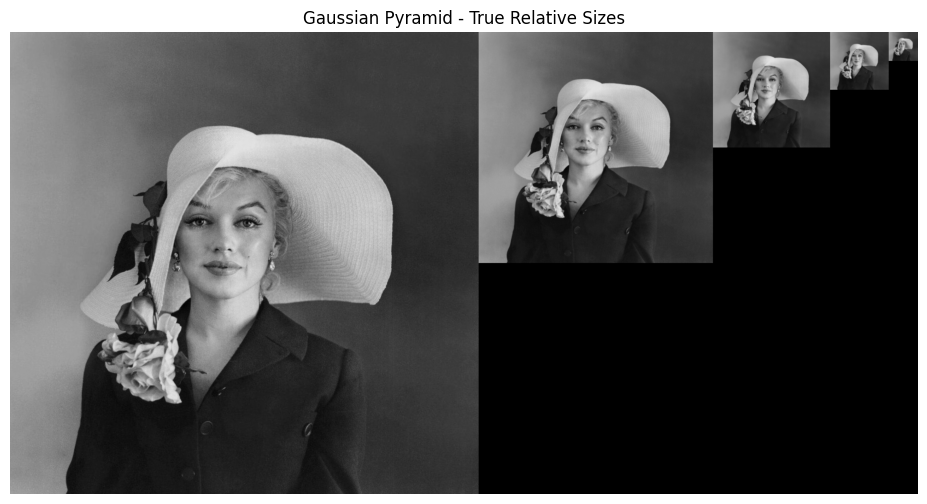

In [ ]:
# Task 1: Gaussian Pyramid
levels = 5

# Start with the original image
gaussian_pyramid = [A]

# Generate the remaining levels
for i in range(levels - 1):

    previous = gaussian_pyramid[-1]  # -1 means the last image in the list

    smaller = cv2.pyrDown(previous) # gaussian smoothing then downsampling

    gaussian_pyramid.append(smaller)

# Print dimensions
for i, image in enumerate(gaussian_pyramid):
    print(f"Level {(i+1)}: {image.shape}")

# Create one canvas with true relative sizes
heights = [image.shape[0] for image in gaussian_pyramid]
widths = [image.shape[1] for image in gaussian_pyramid]

canvas_height = max(heights)
canvas_width = sum(widths)

canvas = np.zeros(
    (canvas_height, canvas_width),
    dtype=np.float64
)

# Paste images into the canvas
x_offset = 0

for image in gaussian_pyramid:

    h, w = image.shape

    canvas[0:h, x_offset:x_offset + w] = image

    x_offset += w

# Display the pyramid
plt.figure(figsize=(15, 6))
plt.imshow(canvas, cmap="gray", vmin=0, vmax=255)
plt.title("Gaussian Pyramid - True Relative Sizes")
plt.axis("off")
plt.show()

In [ ]:
def laplacian_pyramid(img, levels=5):
    gp = [img]
    for i in range(levels - 1):
        gp.append(cv2.pyrDown(gp[-1]))
        #get the last image , apply gaussian smoothing, downsampling, then append to the list

    lp = []
    for i in range(levels - 1):  #compare each 2 levels on gp
        up = cv2.pyrUp(
            gp[i + 1],
            dstsize=(gp[i].shape[1], gp[i].shape[0])
        )  #resize g[i+1] to be the same dimensions of g[i] to compare them (without the details)

        detail = gp[i] - up
        #Li​=Gi​−pyrUp(Gi+1​)

        lp.append(detail)

    lp.append(gp[-1]) #the start point for the reconstruction

    return lp


# Build the Laplacian pyramid
laplacian_levels = laplacian_pyramid(A, levels=5)

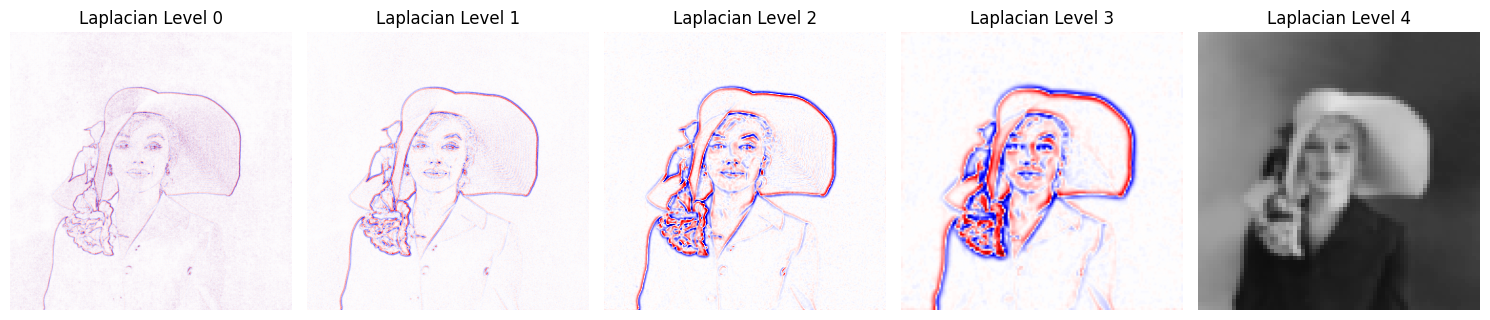

In [ ]:
plt.figure(figsize=(15, 5))

for i, image in enumerate(laplacian_levels):

    plt.subplot(1, 5, i + 1)

    if i < len(laplacian_levels) - 1:

        max_value = np.max(np.abs(image))

        plt.imshow(
            image,
            cmap="seismic",  #diverging colormap
            vmin=-max_value,
            vmax=max_value
        )
# diverging colormap:
  # negative difference: blue, near to 0 difference: white, positive difference: red
    else:
        plt.imshow(image, cmap="gray", vmin=0, vmax=255)

    plt.title(f"Laplacian Level {i}")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
def reconstruct(lp):
    img = lp[-1]
    for L in reversed(lp[:-1]): #reverse from level 0 to level 3, keep level 4 at the end
        #lp=[L3,L2,L1,L0]
        img = cv2.pyrUp(
            img,
            dstsize=(L.shape[1], L.shape[0])
        ) + L   #Gi​=Li​+pyrUp(Gi+1​)

    return img


reconstructed = reconstruct(laplacian_levels)
max_error = np.max(np.abs(A - reconstructed))

print("Maximum Absolute Error:", max_error)

Maximum Absolute Error: 0.0


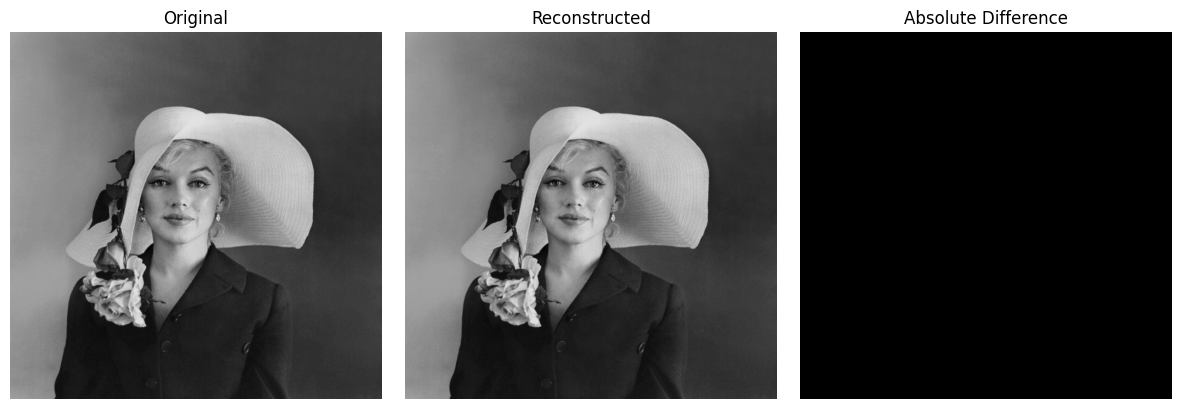

In [ ]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(A, cmap="gray", vmin=0, vmax=255)
plt.title("Original")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(reconstructed, cmap="gray", vmin=0, vmax=255)
plt.title("Reconstructed")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(np.abs(A - reconstructed), cmap="gray")
plt.title("Absolute Difference")
plt.axis("off")

plt.tight_layout()
plt.show()

Each Laplacian level contains the image details lost between two consecutive Gaussian pyramid levels. These details include edges and textures at different scales. By expanding the smallest Gaussian level and adding the stored Laplacian details, the original image can be reconstructed with approximately zero error

In [ ]:
#Task 3
natural = cv2.imread("/content/nature.jpg", cv2.IMREAD_GRAYSCALE).astype(np.float64)
texture = cv2.imread("/content/texture.jpg", cv2.IMREAD_GRAYSCALE).astype(np.float64)

In [ ]:
def spectrum(g):

    F = np.fft.fftshift(np.fft.fft2(g))
    return 20* np.log(np.abs(F)+1)

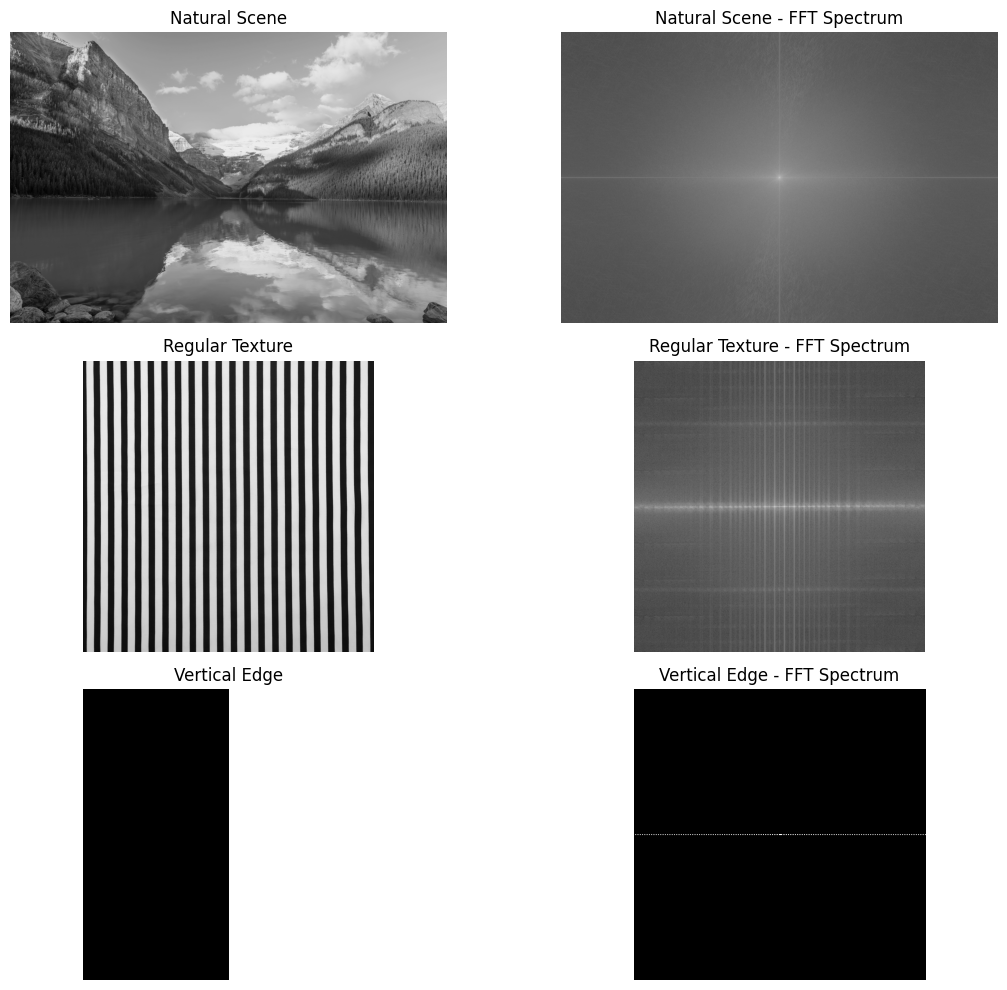

In [ ]:
# Create an image with one vertical edge
edge_image = np.zeros((256, 256), dtype=np.float64)
edge_image[:, 128:] = 255
images = [natural, texture, edge_image]

titles = [
    "Natural Scene",
    "Regular Texture",
    "Vertical Edge"
]

plt.figure(figsize=(12, 10))

for i, image in enumerate(images):

    # Original image
    plt.subplot(3, 2, 2 * i + 1)

    plt.imshow(image, cmap="gray")
    plt.title(titles[i])
    plt.axis("off")

    # Fourier spectrum
    plt.subplot(3, 2, 2 * i + 2)

    plt.imshow(spectrum(image), cmap="gray")
    plt.title(titles[i] + " - FFT Spectrum")
    plt.axis("off")

plt.tight_layout()
plt.show()

The natural scene generally has strong energy near the center of the spectrum because low spatial frequencies represent smooth regions and large-scale image structures.

The regular texture produces distinct peaks or repeated structures in the spectrum because periodic image patterns correspond to specific spatial frequencies.

The vertical edge produces a strong horizontal frequency structure because the intensity changes across the edge, perpendicular to its orientation.

In [ ]:
#Task 4
def circular_masks(shape, radius):
#shape is the freq spectrum
    h, w = shape
# select the center of the spectrum
    center_y = h // 2
    center_x = w // 2

    Y, X = np.ogrid[:h, :w]
    #saving an array for rows coordinates and an array for columns coordinates
    #don't need loops because numpy uses Broadcasting

    distance_squared = (
        (X - center_x) ** 2 +
        (Y - center_y) ** 2
    )  #get the distance between each point and the center of the spectrum
#d^2=(x-cx)^2+(y-cy)^2
    low_mask = (
        distance_squared <= radius ** 2
    ).astype(np.float64)

    high_mask = 1.0 - low_mask

    return low_mask, high_mask

In [ ]:
def frequency_filter(image, radius):

    # Forward Fourier Transform
    F = np.fft.fft2(image)

    # Move low frequencies to the center
    Fs = np.fft.fftshift(F)

    # Create circular masks
    low_mask, high_mask = circular_masks(
        image.shape,
        radius
    )

    # Apply masks
    low_spectrum = Fs * low_mask
    high_spectrum = Fs * high_mask

    # Move the zero frequency back
    low_unshifted = np.fft.ifftshift(low_spectrum)
    high_unshifted = np.fft.ifftshift(high_spectrum)

    # Inverse Fourier Transform
    low_image = np.real(np.fft.ifft2(low_unshifted))
    high_image = np.real(np.fft.ifft2(high_unshifted))

    return low_image, high_image, low_mask, high_mask

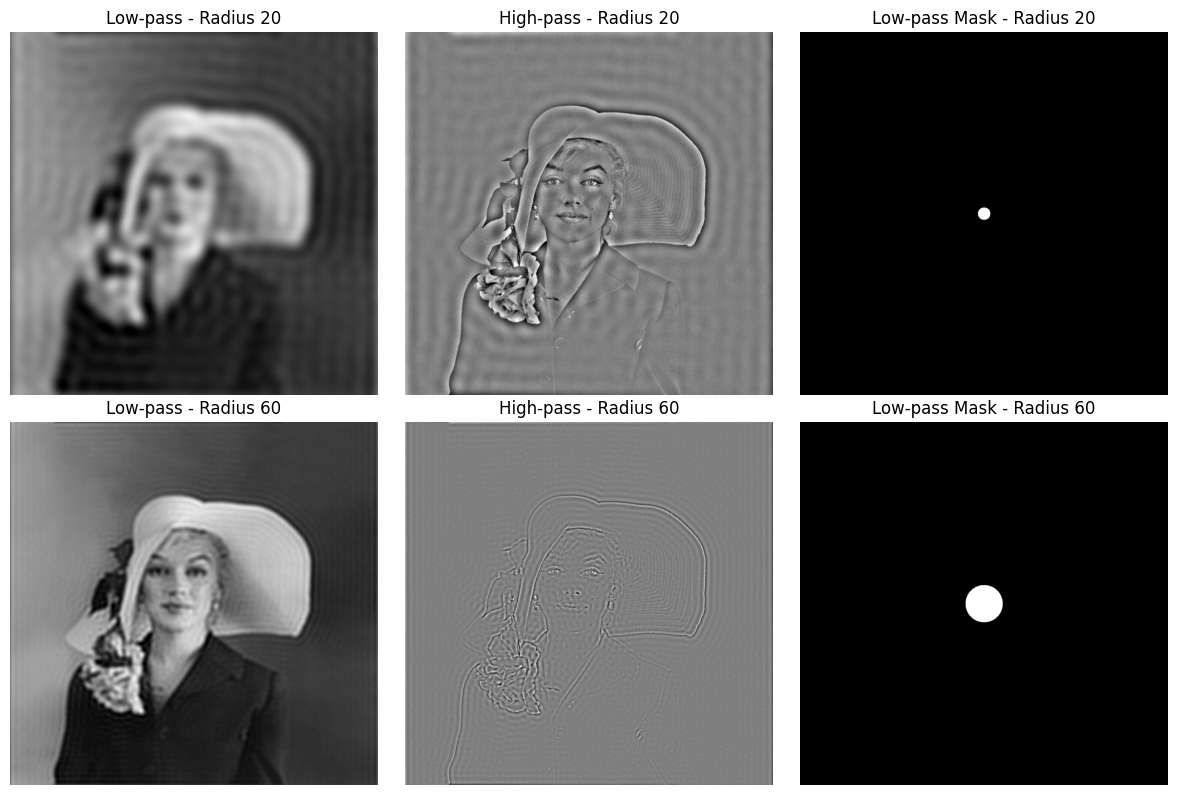

In [ ]:
radii = [20, 60]

plt.figure(figsize=(12, 8))

for i, radius in enumerate(radii):

    low, high, low_mask, high_mask = frequency_filter(
        A,
        radius
    )

    # Low-pass result
    plt.subplot(2, 3, 3 * i + 1)
    plt.imshow(low, cmap="gray", vmin=0, vmax=255)
    plt.title(f"Low-pass - Radius {radius}")
    plt.axis("off")

    # High-pass result
    plt.subplot(2, 3, 3 * i + 2)
    plt.imshow(high, cmap="gray", vmin=-100, vmax=100)
    plt.title(f"High-pass - Radius {radius}")
    plt.axis("off")

    # Circular mask
    plt.subplot(2, 3, 3 * i + 3)
    plt.imshow(low_mask, cmap="gray")
    plt.title(f"Low-pass Mask - Radius {radius}")
    plt.axis("off")

plt.tight_layout()
plt.show()

Low-pass filtering in the frequency domain smooths the image by attenuating high spatial frequencies. This is conceptually similar to Gaussian blur because spatial convolution corresponds to frequency-domain multiplication. However, an ideal circular mask has a sharp cutoff and may introduce ringing artifacts, unlike the smoother Gaussian frequency response